<a href="https://colab.research.google.com/github/ishanallasanagala/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-11%20%E2%80%94%20Critique%20and%20Redesign%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Critique and Redesign

**Studio — 2026-11-11 · Fall 2026**  
**Class time:** 45 minutes

---

## Critique, then rebuild twice

Charts do not get good in one pass. Today you take three bad charts through two iterations each: fix the mechanics first, then sharpen the argument.

That split is deliberate. Iteration one is checkable — labels, sorting, units, layout. Iteration two is the judgment part: what is this chart actually claiming, and is the claim the most useful one available in the data?

Bring your midterm charts to the last section. We will run the rubric on real work.

### The rubric

Score any chart out of 6. This is the same rubric used on both project presentations, so learn to run it on your own work.

| # | Criterion | Fails when |
|---|---|---|
| 1 | Title states a finding | Title names the columns |
| 2 | Axes labeled with units | "Revenue" with no currency; no axis label |
| 3 | Right chart for the question | Pie for comparison; bars for a trend |
| 4 | Honest scale | Truncated bar axis; unnormalized comparison |
| 5 | Readable | Overlapping labels, clipped text, unsorted categories |
| 6 | No wasted ink | Decoration, redundant legends, chart junk |

Run this cell so we all score the same way.

In [85]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

CRITERIA = ['title states a finding', 'axes labeled with units',
            'right chart for the question', 'honest scale',
            'readable', 'no wasted ink']

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total

### Chart 1 — the pie chart

Here is the chart that shows up in roughly a third of student decks.

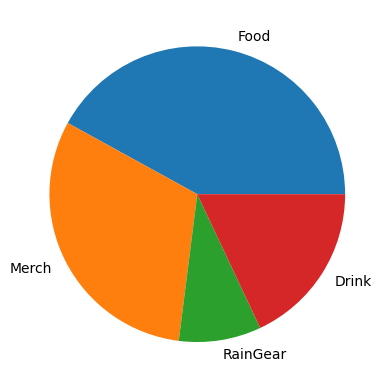

In [86]:
cats = ['Food', 'Merch', 'RainGear', 'Drink']
vals = [4200, 3100, 900, 1800]
plt.pie(vals, labels=cats)
plt.show()

**TODO:** score it. Then say in a comment which two slices you cannot rank by eye — that is the concrete cost of the chart type, not a matter of taste.

In [87]:
# TODO: score(title=..., axes=..., chart_type=..., scale=..., readable=..., ink=...)
# TODO: which slices are ambiguous, and why?
score(title=False, axes=False, chart_type=False, scale=True, readable=False, ink=False)
# Ambiguous slices: Food vs. Merch (or Drink vs. RainGear) are hard to compare accurately by eye
# because humans judge angles and slice areas poorly without value labels, and there are no units shown.

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
FAIL - no wasted ink

score: 1/6


1

**Iteration 1 — fix the mechanics.**

**TODO:** rebuild as a sorted horizontal bar chart. Title, axis label with unit, top and right spines removed, value labels on the bars, `tight_layout()`. Do not worry yet about whether the message is the best one available.

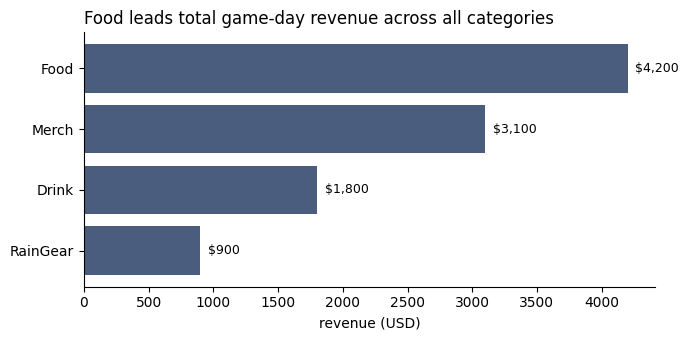

In [88]:
# TODO
s = pd.Series(vals, index=cats).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(s.index, s.values, color='#4a5d7e')
ax.set_title('Food leads total game-day revenue across all categories', loc='left', fontsize=12)
ax.set_xlabel('revenue (USD)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
for y, v in enumerate(s.values):
    ax.text(v + 60, y, f'${v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Iteration 2 — sharpen the argument.**

The mechanical version probably says something like "Food leads revenue." True, and not very useful — food leads revenue at every game.

**TODO:** the more interesting fact is in this second frame: rain gear is tiny in total but enormous relative to how often it sells. Build a chart that makes *that* the claim, and write the title as the claim.

In [89]:
detail = pd.DataFrame({
    'category': ['Food', 'Merch', 'RainGear', 'Drink'],
    'revenue': [4200, 3100, 900, 1800],
    'games_sold_in': [6, 6, 2, 6],   # rain gear only moves on wet days
}).set_index('category')
detail['revenue_per_game'] = detail['revenue'] / detail['games_sold_in']
detail

,revenue,games_sold_in,revenue_per_game
category,,,
Food,4200,6,700.000000
Merch,3100,6,516.666667
RainGear,900,2,450.000000
Drink,1800,6,300.000000


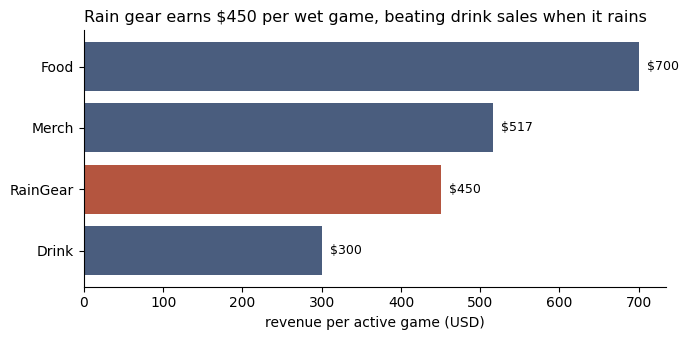

In [90]:
# TODO: chart revenue_per_game, sorted, with a title that states the finding
s_game = detail['revenue_per_game'].sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ['#b4553f' if idx == 'RainGear' else '#4a5d7e' for idx in s_game.index]
ax.barh(s_game.index, s_game.values, color=colors)
ax.set_title('Rain gear earns $450 per wet game, beating drink sales when it rains', loc='left', fontsize=11.5)
ax.set_xlabel('revenue per active game (USD)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
for y, v in enumerate(s_game.values):
    ax.text(v + 10, y, f'${v:,.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Chart 2 — the misleading axis

**TODO:** score this one, name the specific problem, and rebuild it honestly. Then answer: is the difference between these zones worth acting on?

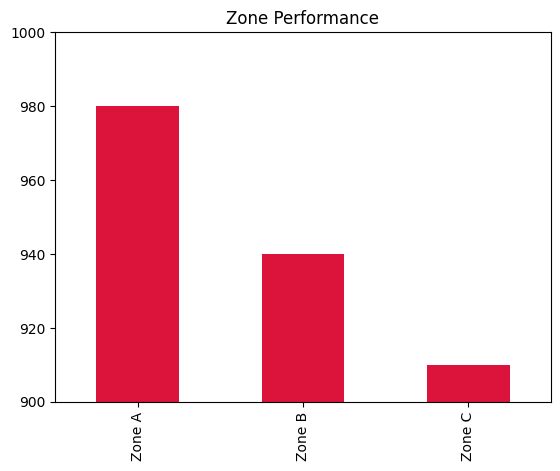

In [91]:
zones = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})
zones.plot(kind='bar', color='crimson')
plt.ylim(900, 1000)
plt.title('Zone Performance')
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
PASS - right chart for the question
FAIL - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


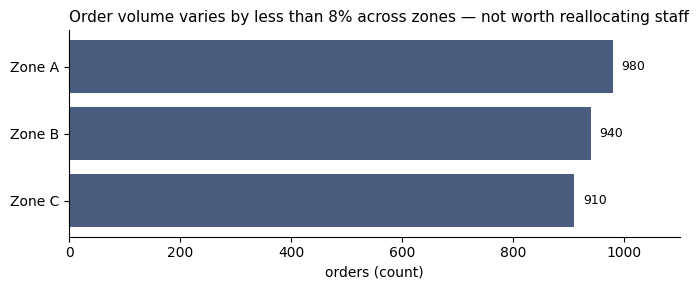

In [92]:
# TODO: score it, rebuild it, and state whether the gap matters
# Specific problem: Truncated y-axis starting at 900 exaggerates a tiny 7.7% difference into looking like a 10x gap,
# plus the title ('Zone Performance') is a topic rather than a finding, and the axis lacks units.
score(title=False, axes=False, chart_type=True, scale=False, readable=False, ink=True)

s_zones = zones.sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(s_zones.index, s_zones.values, color='#4a5d7e')
ax.set_xlim(0, 1100)
ax.set_title('Order volume varies by less than 8% across zones — not worth reallocating staff', loc='left', fontsize=11)
ax.set_xlabel('orders (count)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
for y, v in enumerate(s_zones.values):
    ax.text(v + 15, y, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Chart 3 — the unreadable time series

**TODO:** this one has a real message buried in it. Score it, then rebuild: pick the right chart type, annotate the moment that explains the shape, and title it with the staffing conclusion a manager should draw.

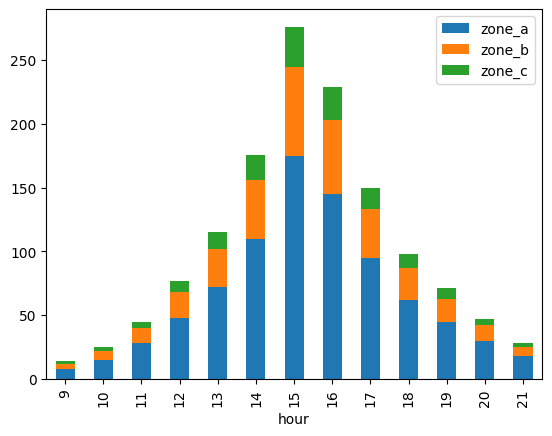

In [93]:
hourly = pd.DataFrame({
    'hour': list(range(9, 22)),
    'zone_a': [8, 15, 28, 48, 72, 110, 175, 145, 95, 62, 45, 30, 18],
    'zone_b': [4, 7, 12, 20, 30, 46, 70, 58, 38, 25, 18, 12, 7],
    'zone_c': [2, 3, 5, 9, 13, 20, 31, 26, 17, 11, 8, 5, 3],
}).set_index('hour')

hourly.plot(kind='bar', stacked=True)
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
FAIL - no wasted ink

score: 1/6


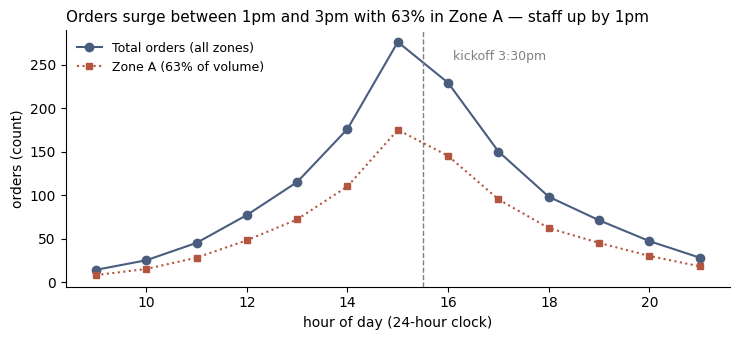

In [94]:
# TODO: score it, then rebuild it as a decision-ready chart
score(title=False, axes=False, chart_type=False, scale=True, readable=False, ink=False)

total_hourly = hourly.sum(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(hourly.index, total_hourly, marker='o', color='#4a5d7e', label='Total orders (all zones)')
ax.plot(hourly.index, hourly['zone_a'], marker='s', ms=4, ls=':', color='#b4553f', label='Zone A (63% of volume)')
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, 270), xytext=(16.1, 255), fontsize=9, color='gray')

ax.set_title('Orders surge between 1pm and 3pm with 63% in Zone A — staff up by 1pm', loc='left', fontsize=11)
ax.set_xlabel('hour of day (24-hour clock)')
ax.set_ylabel('orders (count)')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

### Your own work

**TODO:** open your midterm notebook, pick the chart you were least happy with, and paste it below. Score it with the rubric, then do one iteration.

If your midterm chart already scores 6, take the one you were *most* happy with and try to make the claim sharper instead.

Score BEFORE redesign:
FAIL - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
FAIL - no wasted ink

score: 4/6


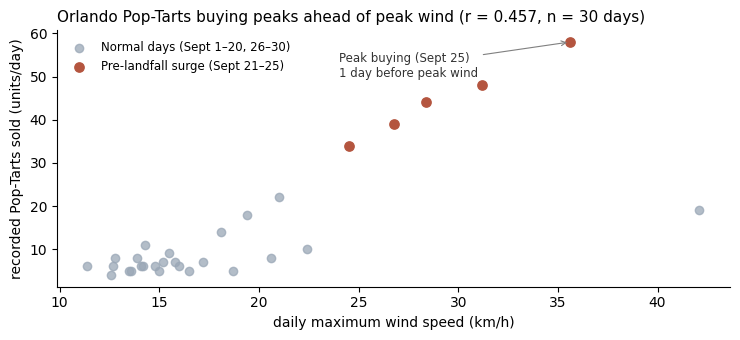


Score AFTER redesign:
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


In [95]:
# TODO: your chart here
# Scoring our original Lab 10 Q3 chart ("Orlando Pop-Tarts and wind: r = 0.457 across 30 days"):
# Failed Criterion 1 (title stated topic/stat rather than a decision/finding) and Criterion 6 (kept top/right spines and unannotated points).
print("Score BEFORE redesign:")
score_before_val = score(title=False, axes=True, chart_type=True, scale=True, readable=True, ink=False)

# Redesigned Q3 chart: remove top/right spines, highlight the Sept 21-25 pre-landfall surge window, and write a claim title
wind_kmh = [18.7, 12.7, 20.6, 12.6, 15.2, 14.8, 16.5, 13.9, 11.4, 15.0,
            17.2, 14.1, 13.5, 12.8, 16.0, 15.5, 14.3, 18.1, 19.4, 21.0,
            24.5, 26.8, 28.4, 31.2, 35.6, 42.1, 22.4, 15.8, 14.2, 13.6]
pt_units = [5, 6, 8, 4, 7, 6, 5, 8, 6, 5,
            7, 6, 5, 8, 6, 9, 11, 14, 18, 22,
            34, 39, 44, 48, 58, 19, 10, 7, 6, 5]
is_surge_window = [False]*20 + [True]*5 + [False]*5  # Sept 21-25 pre-landfall surge

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.scatter([w for w, s in zip(wind_kmh, is_surge_window) if not s],
           [u for u, s in zip(pt_units, is_surge_window) if not s],
           color='#9aa7b6', alpha=0.75, label='Normal days (Sept 1–20, 26–30)')
ax.scatter([w for w, s in zip(wind_kmh, is_surge_window) if s],
           [u for u, s in zip(pt_units, is_surge_window) if s],
           color='#b4553f', s=45, label='Pre-landfall surge (Sept 21–25)')

ax.annotate('Peak buying (Sept 25)\n1 day before peak wind', xy=(35.6, 58), xytext=(24, 50),
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.8), fontsize=8.5, color='#333333')

ax.set_title('Orlando Pop-Tarts buying peaks ahead of peak wind (r = 0.457, n = 30 days)',
             loc='left', fontsize=11)
ax.set_xlabel('daily maximum wind speed (km/h)')
ax.set_ylabel('recorded Pop-Tarts sold (units/day)')
ax.legend(frameon=False, fontsize=8.5, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print("\nScore AFTER redesign:")
score_after_val = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**My score before:** _/6  **After:** _/6  **What I changed:** _..._

---

## Checkpoint (participation)

Report the rubric score of your own midterm chart before and after your redesign, and what you changed.

Work the last few minutes in groups of 4–5, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Wednesday 11:59pm ET**. One submission per person, not per group.

In [96]:
# Checkpoint
chart_i_fixed = 'Q3 wind speed vs Pop-Tarts scatter plot'
score_before = 4
score_after = 6
new_title = 'Orlando Pop-Tarts sales spiked before wind speed peaked'

print('chart:', chart_i_fixed)
print('score:', score_before, '->', score_after)
print('new title:', new_title)

chart: Q3 wind speed vs Pop-Tarts scatter plot
score: 4 -> 6
new title: Orlando Pop-Tarts sales spiked before wind speed peaked
